# End-to-end demo: encode, bind, bundle, recover

A single worked example over a **non-trivial** code --- $p = 3$, $m = 3$, $K = 3$, so none
of the three parameters is at its degenerate value --- followed by the parameter sweeps.

$$N = p^m = 27, \qquad \dim = p^{2m} = 729, \qquad
  \text{codewords} = N^K = 19683$$

Four things happen here:

1. **Encode** real data --- objects with named attributes --- into hypervectors.
2. **Bind** the attributes of one object into a single hypervector, and **recover** the
   attributes back out of it.
3. **Bundle** several whole objects into one hypervector, with the same code, and
   **recover** the set.
4. **Sweep** $m$, $K$ and $p$ to high values and plot every bound against them.

Binding and bundling are different operations with different limits, which is the main
thing this notebook is for:

| | operation | inverse | limited by |
|---|---|---|---|
| **Bind** | point-wise product | read off the message coordinates | nothing --- it is exact and lossless |
| **Bundle** | addition | §IV-A + §IV-B recovery | $u_{\max} = \lfloor\frac{N-1}{K-1}\rfloor = 13$ |

In [1]:
import itertools
import math
import random

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import sage.all__sagemath_modules as _sage_bootstrap    # must precede sage.coding
from sage.coding.grs_code import GeneralizedReedSolomonCode
from sage.coding.guruswami_sudan.gs_decoder import GRSGuruswamiSudanDecoder
from sage.coding.guruswami_sudan.interpolation import gs_interpolation_linalg
from sage.rings.finite_rings.finite_field_constructor import GF

%matplotlib inline
np.set_printoptions(precision=3, suppress=True, linewidth=150)


def load_notebook_defs(path, skip=("plt.show(",)):
    """exec another notebook's code cells, skipping figures and magics."""
    import contextlib, io, json
    nb = json.loads(open(path).read())
    ns = {}
    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue
        src = "".join(cell["source"])
        if any(kw in src for kw in skip):
            continue
        src = "\n".join(("# " + ln) if ln.lstrip()[:1] in ("%", "!") else ln
                        for ln in src.split("\n"))
        try:
            with contextlib.redirect_stdout(io.StringIO()):
                exec(compile(src, path, "exec"), ns)
        except Exception:
            pass
    return ns


enc = load_notebook_defs("encode_m.ipynb")

p, m, K = 3, 3, 3                          # none of these is degenerate
q = N = p ** m
DIM = p ** (2 * m)
tab = enc["gf_tables"](p, m)
vec, ADD, MUL = tab

# Sage's field, forced onto our modulus so the digit encodings agree
F = GF(q, "a", modulus=enc["find_irreducible"](p, m))
GEN = F.gen()


def to_sage(i):
    return sum(int(c) * GEN ** k for k, c in enumerate(vec[i]))


points = [to_sage(j) for j in range(N)]          # our integer order
FROM_SAGE = {points[i]: i for i in range(q)}
assert len(FROM_SAGE) == q
CODE = GeneralizedReedSolomonCode(points, K)
ROOT_FINDER = GRSGuruswamiSudanDecoder(
    CODE, tau=1, interpolation_alg="LinearAlgebra").rootfinding_algorithm()

print(f"p = {p}, m = {m}, K = {K}")
print(f"  N = p^m          = {N}")
print(f"  dim = p^2m       = {DIM}")
print(f"  codewords = N^K  = {N ** K}")
print(f"  {CODE}")
print(f"  modulus          = {enc['find_irreducible'](p, m)}  (low -> high)")

# our encoder still agrees with Sage over F_27
_rng = np.random.default_rng(0)
for _ in range(15):
    u = [int(z) for z in _rng.integers(0, q, K)]
    ours = list(enc["reed_solomon_encode"](u, p, m, tab))
    Rx = F["x"]
    theirs = [FROM_SAGE[Rx([points[c] for c in u])(x)] for x in points]
    assert ours == theirs
print("\nencoder agrees with Sage over F_{3^3}: True")

p = 3, m = 3, K = 3
  N = p^m          = 27
  dim = p^2m       = 729
  codewords = N^K  = 19683
  [27, 3, 25] Reed-Solomon Code over GF(27)
  modulus          = [1, 0, 2, 1]  (low -> high)

encoder agrees with Sage over F_{3^3}: True


## 1. Encoding real data

The paper's §II construction: fix $a$ attributes and give each one a **trivially
intersecting subcode**, meaning each attribute owns its own message coordinates and the
others are zero there. With $K = 3$ we take three attributes, one coordinate each:

$$\texttt{colour} \to u_0, \qquad \texttt{shape} \to u_1, \qquad \texttt{size} \to u_2$$

An *atom* is the hypervector of a message that is zero except in its own attribute's slot.
Value codes start at 1, so that 0 means "this attribute is absent" and cannot be confused
with a real value.

In [2]:
ATTRIBUTES = {
    "colour": ["red", "green", "blue", "amber"],
    "shape":  ["circle", "square", "triangle", "hexagon"],
    "size":   ["small", "medium", "large", "huge"],
}
SLOT = {name: i for i, name in enumerate(ATTRIBUTES)}      # attribute -> coordinate
VALUE_CODE = {(name, v): j + 1                             # 1..4, reserving 0 for absent
              for name, vals in ATTRIBUTES.items()
              for j, v in enumerate(vals)}


def atom_message(attribute, value):
    """Message with `value` in this attribute's slot and 0 elsewhere."""
    u = [0] * K
    u[SLOT[attribute]] = VALUE_CODE[(attribute, value)]
    return u


def atom(attribute, value):
    return enc["histo_encode"](atom_message(attribute, value), p, m, tab)


print(f"{sum(len(v) for v in ATTRIBUTES.values())} atomic values over "
      f"{len(ATTRIBUTES)} attributes; {math.prod(len(v) for v in ATTRIBUTES.values())} "
      f"distinct objects representable")
print(f"the code holds {N ** K} messages, so there is plenty of room\n")
for name in ATTRIBUTES:
    for v in ATTRIBUTES[name][:2]:
        u = atom_message(name, v)
        hv = atom(name, v)
        print(f"  atom({name:<6} = {v:<8}) message {u}  ->  hypervector of dim "
              f"{hv.shape[0]}, |entry| = 1: {np.allclose(np.abs(hv), 1.0)}")

12 atomic values over 3 attributes; 64 distinct objects representable
the code holds 19683 messages, so there is plenty of room

  atom(colour = red     ) message [1, 0, 0]  ->  hypervector of dim 729, |entry| = 1: True
  atom(colour = green   ) message [2, 0, 0]  ->  hypervector of dim 729, |entry| = 1: True
  atom(shape  = circle  ) message [0, 1, 0]  ->  hypervector of dim 729, |entry| = 1: True
  atom(shape  = square  ) message [0, 2, 0]  ->  hypervector of dim 729, |entry| = 1: True
  atom(size   = small   ) message [0, 0, 1]  ->  hypervector of dim 729, |entry| = 1: True
  atom(size   = medium  ) message [0, 0, 2]  ->  hypervector of dim 729, |entry| = 1: True


## 2. Binding, and recovering the attributes

Binding is the point-wise product. Because $\phi$ carries $\mathbb{F}_p$-addition to
multiplication and both code layers are linear, the product of atoms is the hypervector
of the **field sum** of their messages --- and since each attribute occupies a different
coordinate, that sum simply places each value in its own slot:

$$[c,0,0] \boxplus [0,s,0] \boxplus [0,0,z] \;=\; [c,s,z]$$

So recovery is exact and needs no list decoding at all. Decode the hypervector to its
message and read off the coordinates.

In [3]:
def bind(*hypervectors):
    """Binding is the point-wise product."""
    out = hypervectors[0].copy()
    for hv in hypervectors[1:]:
        out = out * hv
    return out


def encode_object(obj):
    """An object is the binding of one atom per attribute."""
    return bind(*[atom(name, v) for name, v in obj.items()])


def decode_hypervector(hv, p, m, tables=None):
    """Hypervector -> RS codeword. Each block is one Hadamard column, so the
    per-position histogram is one-hot and argmax reads off the symbol."""
    H = enc["hadamard_matrix"](p, m, tables)
    N_ = p ** m
    blocks = np.asarray(hv).reshape(N_, N_).T
    hist = np.rint((H.conj().T @ blocks).real / N_).astype(int)
    assert (hist.sum(axis=0) == 1).all(), "not a single codeword"
    return [int(np.argmax(hist[:, j])) for j in range(N_)]


def message_of_codeword(codeword):
    """RS codeword -> message, via Sage's unencode (a Vandermonde solve)."""
    v = CODE.ambient_space()([points[a] for a in codeword])
    assert v in CODE, "not a codeword of this RS code"
    return [FROM_SAGE[c] for c in CODE.unencode(v)]


def read_attributes(message):
    """Message coordinates -> named attribute values."""
    inverse = {(name, code): val for (name, val), code in VALUE_CODE.items()}
    out = {}
    for name, slot in SLOT.items():
        code = message[slot]
        out[name] = inverse.get((name, code), "<absent>" if code == 0 else "<unknown>")
    return out


obj = {"colour": "green", "shape": "triangle", "size": "large"}
bound = encode_object(obj)
print(f"object: {obj}")
print(f"bound hypervector: dim {bound.shape[0]}, |entry| = 1: "
      f"{np.allclose(np.abs(bound), 1.0)}")

# the product really is the encoding of the summed message
expected = [0] * K
for name, v in obj.items():
    expected = [int(ADD[a, b]) for a, b in zip(expected, atom_message(name, v))]
assert np.allclose(bound, enc["histo_encode"](expected, p, m, tab))
print(f"\nbind(atoms) == encode(field sum of messages): True")
print(f"   summed message = {expected}")

# --- recover ------------------------------------------------------------------------
cw = decode_hypervector(bound, p, m, tab)
msg = message_of_codeword(cw)
recovered = read_attributes(msg)
print(f"\nrecovery:")
print(f"   hypervector -> codeword {cw[:9]}...")
print(f"   codeword    -> message  {msg}")
print(f"   message     -> {recovered}")
assert recovered == obj, (recovered, obj)
print(f"\nrecovered exactly, and note nothing was approximate: binding is lossless.")

object: {'colour': 'green', 'shape': 'triangle', 'size': 'large'}
bound hypervector: dim 729, |entry| = 1: True

bind(atoms) == encode(field sum of messages): True
   summed message = [2, 3, 3]

recovery:
   hypervector -> codeword [2, 8, 2, 19, 16, 1, 1, 16, 19]...
   codeword    -> message  [2, 3, 3]
   message     -> {'colour': 'green', 'shape': 'triangle', 'size': 'large'}

recovered exactly, and note nothing was approximate: binding is lossless.


In [4]:
# every object round-trips, not just the one above
allobj = [dict(zip(ATTRIBUTES, combo))
          for combo in itertools.product(*ATTRIBUTES.values())]
bad = 0
for o in allobj:
    got = read_attributes(message_of_codeword(decode_hypervector(encode_object(o), p, m, tab)))
    bad += got != o
print(f"round-tripped all {len(allobj)} objects through bind -> recover: "
      f"{len(allobj) - bad} correct, {bad} wrong")
assert bad == 0

# binding is commutative and associative, being a point-wise product
a1, a2, a3 = (atom("colour", "red"), atom("shape", "square"), atom("size", "huge"))
assert np.allclose(bind(a1, a2, a3), bind(a3, a1, a2))
assert np.allclose(bind(bind(a1, a2), a3), bind(a1, bind(a2, a3)))
print("binding is commutative and associative: True")

# and it is invertible on its own: dividing out an atom removes it
assert np.allclose(bind(a1, a2) * np.conj(a2), a1 * (np.abs(a2) ** 2))
print("an atom can be divided back out (conjugate = inverse, since |entry| = 1): True")

round-tripped all 64 objects through bind -> recover: 64 correct, 0 wrong
binding is commutative and associative: True
an atom can be divided back out (conjugate = inverse, since |entry| = 1): True


## 3. Bundling, with the same code

Bundling is addition, and unlike binding it is **lossy** --- the sum of $t$ hypervectors
is not the hypervector of anything. Recovering the set takes the two-stage machinery:

- **§IV-A** --- invert the Hadamard block-wise, $h_j = \frac1N H^\dagger s_j$, giving the
  per-position histogram of symbols.
- **§IV-B** --- Sidorenko--Fischer Algorithm 2 on $M = dY$, then reject candidates scoring
  below $dN$.

These are the same functions as [sidorenko_fischer.ipynb](sidorenko_fischer.ipynb),
repeated here so this notebook stands alone. For this code
$u_{\max} = \lfloor\frac{N-1}{K-1}\rfloor = 13$, so a bundle of a few objects is well
inside the limit.

In [5]:
def histograms_from_superposition(sup, p, m, tables=None):
    """Section IV-A: h_j = (1/N) H^dagger s_j."""
    H = enc["hadamard_matrix"](p, m, tables)
    N_ = p ** m
    return np.rint((H.conj().T @ np.asarray(sup).reshape(N_, N_).T).real / N_).astype(int)


def support_matrix(hist):
    """Y: the disjunctive channel output, y[a,j] = 1 iff h[a,j] > 0."""
    return (hist > 0).astype(int)


def score(codeword, M):
    """<W(c), M>."""
    return sum(int(M[int(a), j]) for j, a in enumerate(codeword))


def ks_list_decode(Y, d, p, m, K, points, root_finder, from_sage,
                   agree=None, ell_max=40):
    """Section IV-B: Sidorenko-Fischer Alg. 2, then reject the low scorers."""
    N_ = p ** m
    if agree is None:
        agree = N_
    P = [(points[j], points[a])
         for j in range(N_) for a in range(Y.shape[0]) if Y[a, j]]
    for ell in range(2, ell_max):
        try:
            Q = gs_interpolation_linalg(P, len(P) - agree, (d, ell), K - 1)
        except (IndexError, ValueError):
            continue
        kept = [f for f in root_finder(Q, maxd=K - 1)
                if score([from_sage[f(x)] for x in points], d * Y) >= d * agree]
        return kept, len(P), ell
    raise RuntimeError(f"no interpolation polynomial up to ell = {ell_max}")


def message_of_poly(f):
    zero = F.zero()
    coeffs = list(f.list()) + [zero] * (K - len(f.list()))
    return [FROM_SAGE[c] for c in coeffs]


SCENE = [
    {"colour": "red",   "shape": "circle",   "size": "small"},
    {"colour": "blue",  "shape": "square",   "size": "large"},
    {"colour": "green", "shape": "triangle", "size": "huge"},
    {"colour": "amber", "shape": "hexagon",  "size": "medium"},
]
t = len(SCENE)
u_max = (N - 1) // (K - 1)
l_max = (2 * N - (N - K + 1)) / (2 * (K - 1))
print(f"bundling t = {t} objects;  u_max = {u_max}, l_max = {l_max:.2f}")

bundle = sum(encode_object(o) for o in SCENE)
print(f"bundle: dim {bundle.shape[0]}, and note |entry| != 1 any more "
      f"(range {np.abs(bundle).min():.2f} .. {np.abs(bundle).max():.2f})")

hist = histograms_from_superposition(bundle, p, m, tab)
assert (hist.sum(axis=0) == t).all(), "every column must sum to t"
print(f"\nIV-A: recovered histograms, {hist.shape[0]} x {hist.shape[1]}; "
      f"column sums all equal t = {t}: True")
print(f"      (t is read off the data, it was never supplied)")

Y = support_matrix(hist)
got, n_P, ell = ks_list_decode(Y, 1, p, m, K, points, ROOT_FINDER, FROM_SAGE)
print(f"\nIV-B: interpolated over n_P = {n_P} points, ell = {ell}; "
      f"{len(got)} candidate(s) survived")

recovered_objs = [read_attributes(message_of_poly(f)) for f in got]
for o in recovered_objs:
    print(f"   recovered {o}")
key = lambda o: tuple(sorted(o.items()))
assert sorted(recovered_objs, key=key) == sorted(SCENE, key=key)
print(f"\nexactly the {t} bundled objects, nothing spurious: True")

bundling t = 4 objects;  u_max = 13, l_max = 7.25
bundle: dim 729, and note |entry| != 1 any more (range 1.00 .. 4.00)

IV-A: recovered histograms, 27 x 27; column sums all equal t = 4: True
      (t is read off the data, it was never supplied)



IV-B: interpolated over n_P = 100 points, ell = 4; 4 candidate(s) survived
   recovered {'colour': 'green', 'shape': 'triangle', 'size': 'huge'}
   recovered {'colour': 'red', 'shape': 'circle', 'size': 'small'}
   recovered {'colour': 'blue', 'shape': 'square', 'size': 'large'}
   recovered {'colour': 'amber', 'shape': 'hexagon', 'size': 'medium'}

exactly the 4 bundled objects, nothing spurious: True


In [6]:
# the inner-product readout, for contrast: it only tests membership, and it is
# already past its guarantee here since t = 4 > l_max = 2.75
print(f"similarity readout: t = {t} is inside l_max = {l_max:.2f}, so this is")
print(f"guaranteed to separate -- and it does, comfortably.")
norm_b = np.linalg.norm(bundle)
absent = [{"colour": "red", "shape": "square", "size": "huge"},
          {"colour": "blue", "shape": "hexagon", "size": "small"}]
rows = []
for o in SCENE + absent:
    hv = encode_object(o)
    sim = abs(np.vdot(hv, bundle)) / (np.linalg.norm(hv) * norm_b)
    rows.append((o in SCENE, sim))
    tag = "in bundle " if o in SCENE else "absent    "
    print(f"   {tag} similarity {sim:.3f}   {list(o.values())}")
lo = min(s for inb, s in rows if inb)
hi = max(s for inb, s in rows if not inb)
print(f"\n   weakest member {lo:.3f} vs strongest non-member {hi:.3f} -> "
      f"{'separated' if lo > hi else 'NOT separated'}")
print("   Even where it works, this answers only 'is X present?'. It cannot list")
print("   the contents -- that is what IV-B above is for.")

similarity readout: t = 4 is inside l_max = 7.25, so this is
guaranteed to separate -- and it does, comfortably.
   in bundle  similarity 0.536   ['red', 'circle', 'small']
   in bundle  similarity 0.536   ['blue', 'square', 'large']
   in bundle  similarity 0.501   ['green', 'triangle', 'huge']
   in bundle  similarity 0.570   ['amber', 'hexagon', 'medium']
   absent     similarity 0.086   ['red', 'square', 'huge']
   absent     similarity 0.086   ['blue', 'hexagon', 'small']

   weakest member 0.501 vs strongest non-member 0.086 -> separated
   Even where it works, this answers only 'is X present?'. It cannot list
   the contents -- that is what IV-B above is for.


### Where each bound actually bites

Two capacities, two very different characters. Pushing $t$ up from 4 to 16 shows it:
$l_{\max} = 7.25$ is conservative in the familiar way --- the similarity margin narrows
but never closes --- while $u_{\max} = 13$ is a **hard cliff**, and it lands exactly where
the formula says.

In [7]:
ALL_OBJECTS = [dict(zip(ATTRIBUTES, combo))
               for combo in itertools.product(*ATTRIBUTES.values())]
print(f"l_max = {l_max:.2f}   u_max = {u_max}   "
      f"({len(ALL_OBJECTS)} objects to draw from)\n")
print(f"{'t':>3} {'min member':>11} {'max absent':>11} {'margin':>8} "
      f"{'readout':>10} {'IV-B recovery':>22}")
print("-" * 70)
for t_try in (4, 8, 12, 13, 14, 16):
    rng_t = np.random.default_rng(7)
    scene_t = [ALL_OBJECTS[i]
               for i in rng_t.choice(len(ALL_OBJECTS), t_try, replace=False)]
    bun = sum(encode_object(o) for o in scene_t)
    nb_ = np.linalg.norm(bun)
    ins = [abs(np.vdot(encode_object(o), bun)) / (np.sqrt(DIM) * nb_) for o in scene_t]
    outs = [abs(np.vdot(encode_object(o), bun)) / (np.sqrt(DIM) * nb_)
            for o in ALL_OBJECTS if o not in scene_t]
    Yt = support_matrix(histograms_from_superposition(bun, p, m, tab))
    try:
        gt, _, _ = ks_list_decode(Yt, 1, p, m, K, points, ROOT_FINDER, FROM_SAGE)
        rec_t = [read_attributes(message_of_poly(f)) for f in gt]
        key_t = lambda o: tuple(sorted(o.items()))
        verdict = (f"exact, list of {len(gt)}"
                   if sorted(rec_t, key=key_t) == sorted(scene_t, key=key_t)
                   else f"WRONG set of {len(gt)}")
    except RuntimeError:
        verdict = "FAILS: no interpolant"
    print(f"{t_try:>3} {min(ins):>11.3f} {max(outs):>11.3f} "
          f"{min(ins) - max(outs):>8.3f} "
          f"{'separated' if min(ins) > max(outs) else 'MERGED':>10} {verdict:>22}")

print(f"\nThe readout separates at every t tried; its margin merely shrinks, the same")
print(f"conservatism encode_m.ipynb measured for l_max. IV-B instead stops dead:")
print(f"t = {u_max} recovers, t = {u_max + 1} cannot -- the Kautz-Singleton strength is")
print(f"a real cliff, and Example 2 in sidorenko_fischer.ipynb is why it has to be.")

l_max = 7.25   u_max = 13   (64 objects to draw from)

  t  min member  max absent   margin    readout          IV-B recovery
----------------------------------------------------------------------


  4       0.514       0.142    0.372  separated       exact, list of 4


  8       0.373       0.158    0.215  separated       exact, list of 8


 12       0.314       0.183    0.131  separated      exact, list of 12


 13       0.306       0.182    0.124  separated      exact, list of 13


 14       0.305       0.172    0.133  separated  FAILS: no interpolant


 16       0.262       0.187    0.075  separated  FAILS: no interpolant

The readout separates at every t tried; its margin merely shrinks, the same
conservatism encode_m.ipynb measured for l_max. IV-B instead stops dead:
t = 13 recovers, t = 14 cannot -- the Kautz-Singleton strength is
a real cliff, and Example 2 in sidorenko_fischer.ipynb is why it has to be.


## 4. The bounds, and how they move with $m$, $K$, $p$

Everything in the construction is a function of $N = p^m$ and $K$. Definitions, all as
used above:

| Quantity | Formula | Meaning |
|---|---|---|
| $N$ | $p^m$ | block length: Reed--Solomon symbols per codeword |
| $\dim$ | $N^2 = p^{2m}$ | hypervector length --- what you pay |
| size | $N^K = p^{mK}$ | number of codewords, i.e. nameable items |
| $d_{\min}$ | $N-K+1$ | RS minimum distance; MDS, so exact |
| $\mu$ | $\dfrac{K-1}{N}$ | coherence (Prop. 1): worst normalised overlap of two codewords |
| $l_{\max}$ | $\dfrac{2N-d_{\min}}{2(N-d_{\min})}$ | items a **similarity readout** can separate |
| $u_{\max}$ | $\left\lfloor\dfrac{N-1}{K-1}\right\rfloor$ | distinct codewords **§IV-B can reconstruct**; the KS strength |
| unique radius | $\left\lfloor\dfrac{d_{\min}-1}{2}\right\rfloor$ | errors classical RS decoding corrects |
| Johnson | $N-\sqrt{N(K-1)}$ | ceiling on list-decoding radius |

The three sweeps below vary one parameter at a time, to high values. Note the two
capacities $l_{\max}$ and $u_{\max}$ answer different questions and move together but
never coincide.

In [8]:
def d_min(N_, K_):    return N_ - K_ + 1
def mu(N_, K_):       return (K_ - 1) / N_
def l_max_f(N_, K_):  return float("inf") if K_ == 1 else (2 * N_ - d_min(N_, K_)) / (2 * (K_ - 1))
def u_max_f(N_, K_):  return float("inf") if K_ == 1 else (N_ - 1) // (K_ - 1)
def johnson(N_, K_):  return N_ - math.sqrt(N_ * (K_ - 1))
def unique_r(N_, K_): return (d_min(N_, K_) - 1) // 2

MODE = "light"
PALETTE = {
    "light": {"surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e",
              "grid": "#dcdbd6", "series": ["#2a78d6", "#eb6834", "#1baf7a"]},
    "dark":  {"surface": "#1a1a19", "ink": "#ffffff", "ink2": "#c3c2b7",
              "grid": "#3a3a38", "series": ["#3987e5", "#d95926", "#199e70"]},
}
PAL = PALETTE[MODE]
mpl.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"],
    "text.color": PAL["ink"], "axes.labelcolor": PAL["ink2"],
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"],
    "axes.edgecolor": PAL["grid"], "grid.color": PAL["grid"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linewidth": 0.6, "grid.alpha": 0.9,
    "lines.linewidth": 2.0, "lines.markersize": 5,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 130,
})
import os
os.makedirs("figures", exist_ok=True)

from sympy import primerange
SWEEPS = [
    ("vary $m$  ($p=3$, $K=3$)", "$m$",
     [(mm, 3 ** mm, 3) for mm in range(1, 11)]),
    ("vary $K$  ($p=2$, $m=8$, $N=256$)", "$K$",
     [(KK, 256, KK) for KK in range(2, 65)]),
    ("vary $p$  ($m=2$, $K=3$)", "$p$",
     [(pp, pp ** 2, 3) for pp in primerange(2, 102)]),
]
print("sweep sizes:", [(lab.split()[1], len(rows)) for lab, _, rows in SWEEPS])
print(f"largest N reached: {max(max(N_ for _, N_, _ in rows) for _, _, rows in SWEEPS)}")

sweep sizes: [('$m$', 10), ('$K$', 63), ('$p$', 26)]
largest N reached: 59049


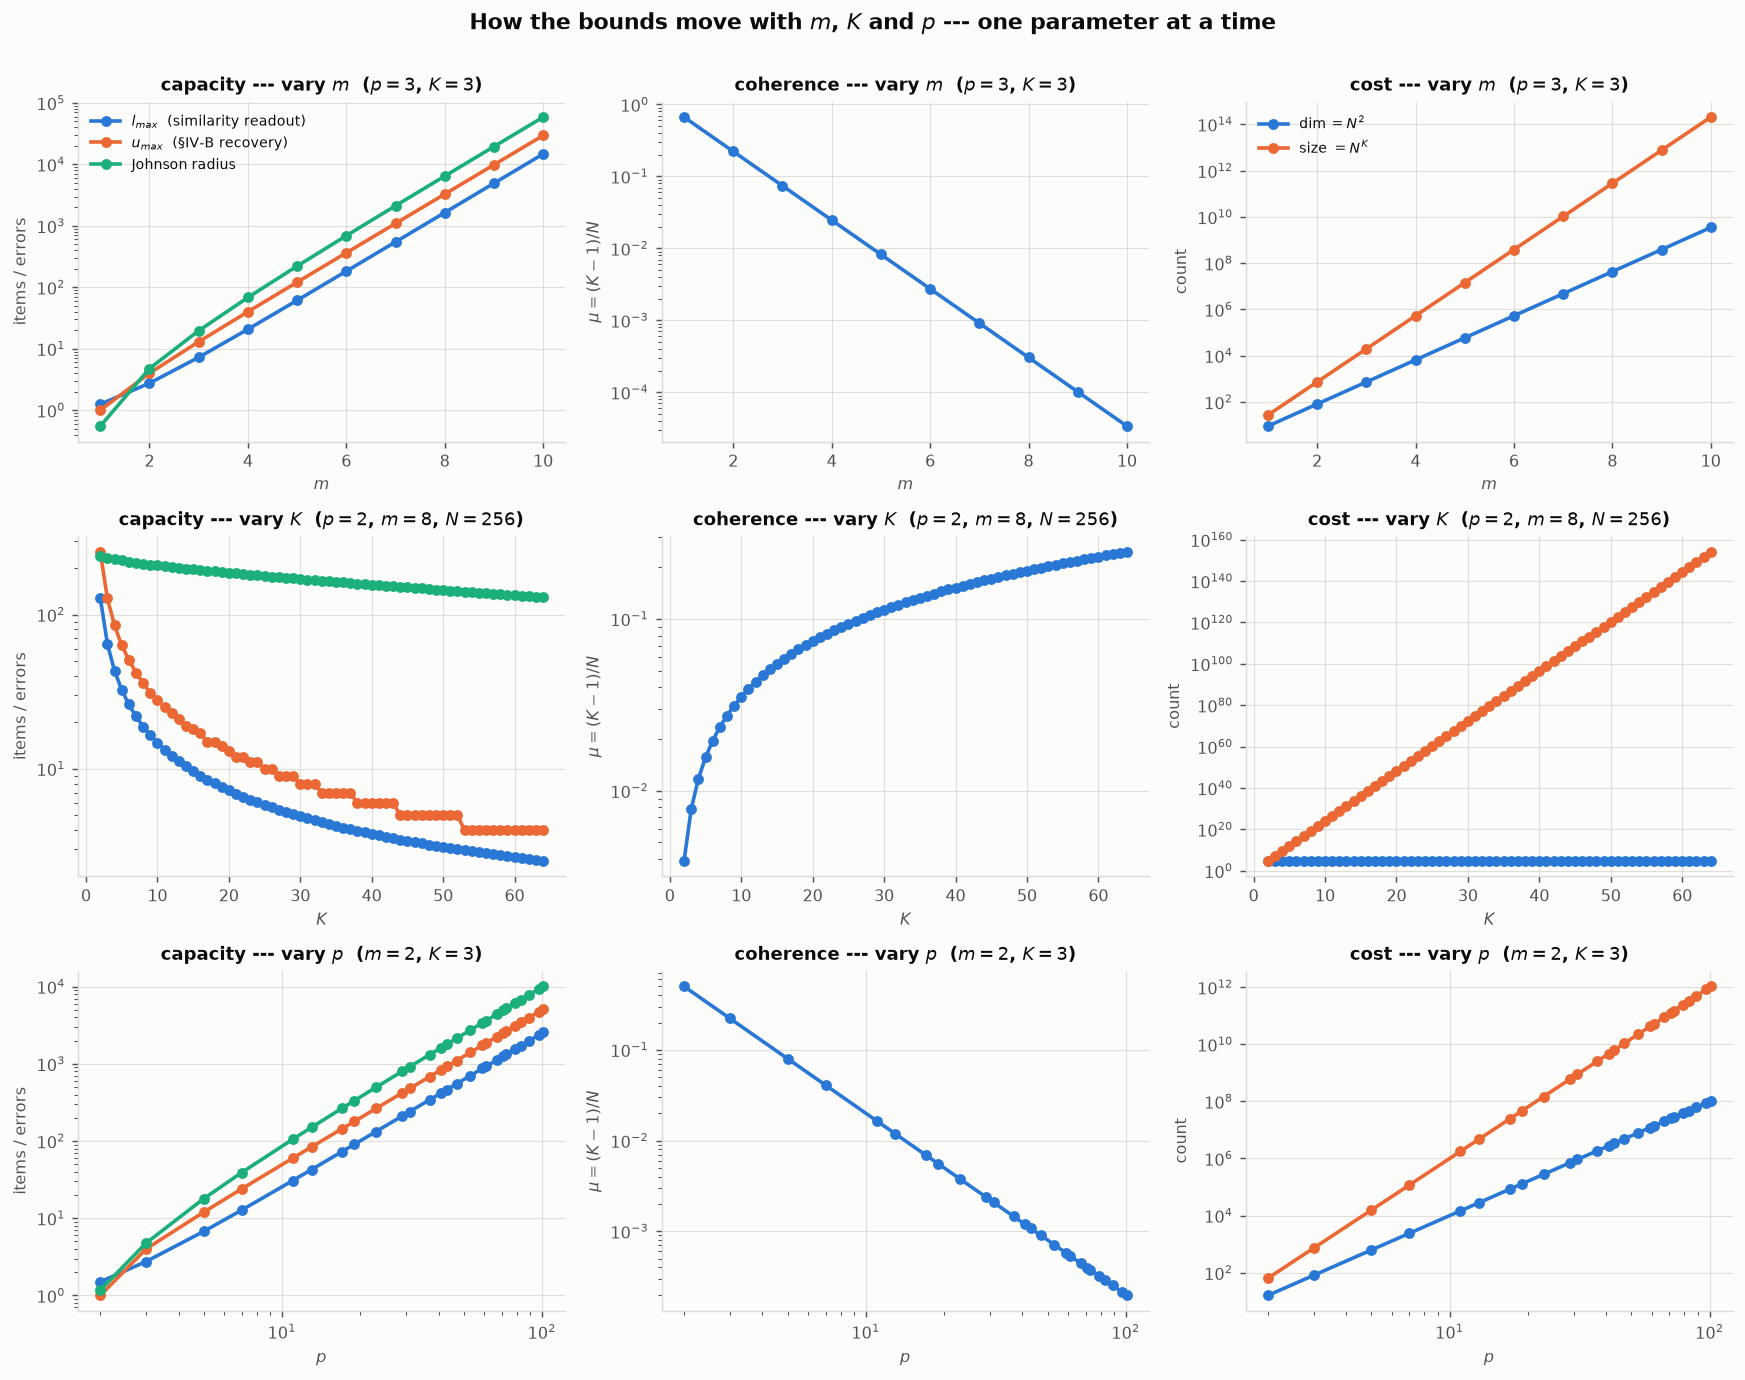

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(13.5, 10.5))

for r, (title, xlabel, rows) in enumerate(SWEEPS):
    xs = [x for x, _, _ in rows]
    Ns = [N_ for _, N_, _ in rows]
    Ks = [K_ for _, _, K_ in rows]

    # --- column 1: the two capacities, plus the list-decoding ceiling -------------
    ax = axes[r][0]
    ax.plot(xs, [l_max_f(n, k) for n, k in zip(Ns, Ks)],
            color=PAL["series"][0], marker="o", label="$l_{max}$  (similarity readout)")
    ax.plot(xs, [u_max_f(n, k) for n, k in zip(Ns, Ks)],
            color=PAL["series"][1], marker="o", label="$u_{max}$  (§IV-B recovery)")
    ax.plot(xs, [johnson(n, k) for n, k in zip(Ns, Ks)],
            color=PAL["series"][2], marker="o", label="Johnson radius")
    ax.set_yscale("log")
    ax.set_ylabel("items / errors")
    ax.set_title(f"capacity --- {title}")
    if r == 0:
        ax.legend(loc="upper left", fontsize=8)

    # --- column 2: coherence ------------------------------------------------------
    ax = axes[r][1]
    ax.plot(xs, [mu(n, k) for n, k in zip(Ns, Ks)],
            color=PAL["series"][0], marker="o")
    ax.set_yscale("log")
    ax.set_ylabel("$\\mu = (K-1)/N$")
    ax.set_title(f"coherence --- {title}")

    # --- column 3: what it costs --------------------------------------------------
    ax = axes[r][2]
    ax.plot(xs, [n ** 2 for n in Ns], color=PAL["series"][0], marker="o",
            label="$\\dim = N^2$")
    ax.plot(xs, [float(n) ** k for n, k in zip(Ns, Ks)], color=PAL["series"][1],
            marker="o", label="size $= N^K$")
    ax.set_yscale("log")
    ax.set_ylabel("count")
    ax.set_title(f"cost --- {title}")
    if r == 0:
        ax.legend(loc="upper left", fontsize=8)

    for c in range(3):
        axes[r][c].set_xlabel(xlabel)
        if r == 2:
            axes[r][c].set_xscale("log")

fig.suptitle("How the bounds move with $m$, $K$ and $p$ --- one parameter at a time",
             y=1.005, fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig("figures/demo_sweeps.png", bbox_inches="tight")
plt.show()

In [10]:
# the same numbers, so nothing depends on reading a log axis
for title, xlabel, rows in SWEEPS:
    print(f"\n{title.replace('$','')}")
    print(f"{xlabel.strip('$'):>4} {'N':>7} {'K':>4} {'mu':>9} {'l_max':>9} "
          f"{'u_max':>7} {'johnson':>9} {'unique':>7} {'dim':>12} {'size':>12}")
    print("-" * 88)
    keep = rows if len(rows) <= 8 else rows[::max(1, len(rows) // 7)]
    for x, n, k in keep:
        print(f"{x:>4} {n:>7} {k:>4} {mu(n, k):>9.5f} {l_max_f(n, k):>9.2f} "
              f"{u_max_f(n, k):>7} {johnson(n, k):>9.1f} {unique_r(n, k):>7} "
              f"{n ** 2:>12} {float(n) ** k:>12.3g}")


vary m  (p=3, K=3)
   m       N    K        mu     l_max   u_max   johnson  unique          dim         size
----------------------------------------------------------------------------------------
   1       3    3   0.66667      1.25       1       0.6       0            9           27
   2       9    3   0.22222      2.75       4       4.8       3           81          729
   3      27    3   0.07407      7.25      13      19.7      12          729     1.97e+04
   4      81    3   0.02469     20.75      40      68.3      39         6561     5.31e+05
   5     243    3   0.00823     61.25     121     221.0     120        59049     1.43e+07
   6     729    3   0.00274    182.75     364     690.8     363       531441     3.87e+08
   7    2187    3   0.00091    547.25    1093    2120.9    1092      4782969     1.05e+10
   8    6561    3   0.00030   1640.75    3280    6446.4    3279     43046721     2.82e+11
   9   19683    3   0.00010   4921.25    9841   19484.6    9840    387420489     

## Reading the sweeps

**Varying $m$ (top row), $p$ and $K$ fixed.** $N = p^m$ grows exponentially, so every
capacity grows exponentially and $\mu$ decays exponentially --- $m$ is the cheapest
parameter to raise *in terms of capacity per unit of $m$*, and the most expensive in
absolute terms, since $\dim = p^{2m}$ grows just as fast. Adding 1 to $m$ multiplies the
dimension by $p^2$.

**Varying $K$ (middle row), $N$ fixed at 256.** The only row where the capacities go
**down**. $\mu = (K-1)/N$ rises linearly, so $l_{\max}$ and $u_{\max}$ fall roughly as
$1/K$, while size $= N^K$ climbs exponentially. This is the real trade in the whole
construction: $K$ converts bundling capacity into vocabulary at a brutal exchange rate,
and it is why $K = 2$ or $3$ is almost always right. Note $\dim$ is flat --- raising $K$
costs nothing in dimension, which is exactly why the temptation exists.

**Varying $p$ (bottom row), $m$ and $K$ fixed.** Same shape as the $m$ sweep but slower:
$N = p^2$ grows polynomially rather than exponentially. Capacity per unit of *dimension*
is what matters, and that is identical in the two rows --- both reach a given $N$ and
$\dim = N^2$ follows. The choice between raising $p$ and raising $m$ is about the
alphabet, not the capacity: large $p$ with $m=1$ means many distinct complex phases,
small $p$ with large $m$ means few.

**The two capacities never coincide.** $u_{\max}$ sits above $l_{\max}$ everywhere, by a
factor approaching 2. They answer different questions: $l_{\max}$ asks whether an inner
product can *detect* an item, $u_{\max}$ whether §IV-B can *reconstruct* the whole set.

For this code they are $7.25$ and $13$, and the sweep above shows they behave quite
differently in practice. $l_{\max}$ is conservative: the readout still separated cleanly
at $t = 16$, more than double it. $u_{\max}$ is not conservative at all --- recovery is
exact at $t = 13$ and impossible at $t = 14$. So the detect-only bound is loose and the
reconstruct bound is tight, which is worth knowing before budgeting either.